<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta7_g%C3%B6rev2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: Tesla T4


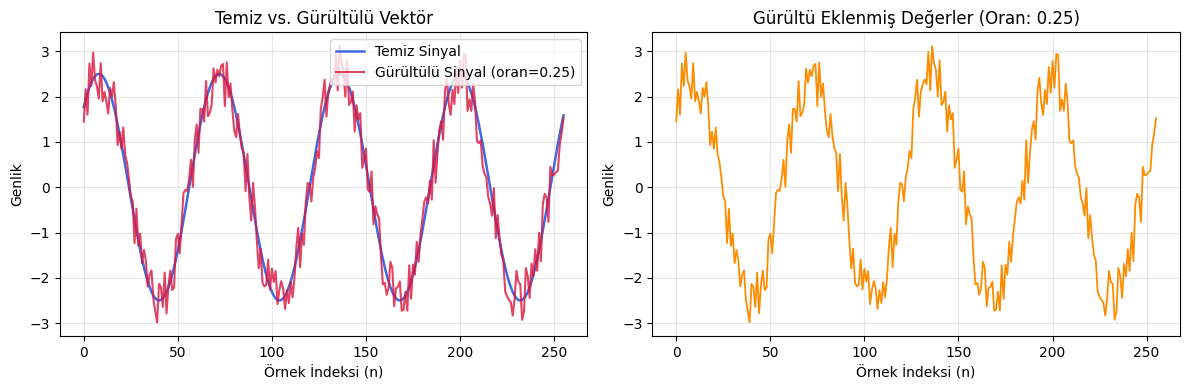

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def doldur_sinus(vec, amplitude=2.5, frequency=4.0, phase=np.pi/4, fs=256.0):
    n = len(vec)
    if n <= 0 or (n & (n - 1)) != 0:
        raise ValueError("Vektör boyutu 2'nin kuvveti olmalıdır.")
    t = np.arange(n, dtype=np.float64) / fs
    vec[:] = amplitude * np.sin(2.0 * np.pi * frequency * t + phase)
    return vec

def gurultu_ekle(vec, noise_ratio):
    """
    vec         : Girdi vektörü
    noise_ratio : [0, 1] aralığında gürültü oranı
    """
    if not (0.0 <= noise_ratio <= 1.0):
        raise ValueError("Gürültü oranı [0, 1] aralığında olmalıdır.")

    vec_arr = np.asarray(vec, dtype=np.float64)
    peak_amp = np.max(np.abs(vec_arr))
    if peak_amp == 0:
        peak_amp = 1.0

    noise = np.random.uniform(-1.0, 1.0, size=vec_arr.shape) * (noise_ratio * peak_amp)
    return vec_arr + noise

N = 256
clean_vec = np.zeros(N, dtype=np.float64)
doldur_sinus(clean_vec, amplitude=2.5, frequency=4.0, phase=np.pi/4, fs=N)

noise_ratio = 0.25
noisy_vec = gurultu_ekle(clean_vec, noise_ratio)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(clean_vec, label='Temiz Sinyal', color='royalblue', linewidth=1.8)
plt.plot(noisy_vec, label=f'Gürültülü Sinyal (oran={noise_ratio})', color='crimson', alpha=0.8)
plt.title('Temiz vs. Gürültülü Vektör')
plt.xlabel('Örnek İndeksi (n)')
plt.ylabel('Genlik')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(noisy_vec, color='darkorange', linewidth=1.3)
plt.title(f'Gürültü Eklenmiş Değerler (Oran: {noise_ratio})')
plt.xlabel('Örnek İndeksi (n)')
plt.ylabel('Genlik')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()